# 🔐 KeyPrint Guard & Arena: 타이핑 지문(Keystroke Dynamics) 기반 해커 침입 차단(1:1) 및 타자연습 인물 자동 식별(1:N) 공식 검증 노트북
- **학번 / 이름**: 201935607 김대현
- **노트북 역할 (Non-Retraining Canonical Verification)**:
  - 본 노트북은 재실행 시 가중치가 달라지는 중복 재학습을 수행하지 않고, 공식 파이프라인(`src/visualize_and_run.py`, `src/eval_password_calibration.py`, `src/eval_typing_style.py`)이 생성한 **정규 가중치(`.pt`, `.onnx`)·학습 에포크 로그(`histories`)·평가 리포트 JSON 3종**을 로드하여 **실시간 순방향 추론 재현성(`±1e-5`)과 전 구간 지표를 검증**합니다.
- **데이터셋**:
  1. **CMU Keystroke Dynamics Benchmark** (`20,400` 세션 = `51명 × 8세션 × 50회`, 고정 암호 `.tie5Roanl`, 학술 공개)
  2. **KeyRecs Multi-Session Sentence & Fixed-Text Dataset** (Zenodo `10.5281/zenodo.7886742`, CC-BY 4.0, 원시 `99명 × 2세션` 자유 필사 `562,596` 데이터 라인 = 유효 전이 `562,398`행 + 세션 종단 타건 `198`행 → 무오타 비중첩 `25자` 문장 시퀀스 통과 `96명` + 고정 문자열 `vpwjkeurkb`)
---

## 1. 실험 환경 설정 및 원시 이중 코퍼스 로드

In [1]:
import hashlib, json, os, sys, tempfile, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import onnxruntime as ort
from sklearn.metrics import silhouette_score
from IPython.display import Image, display as ipy_display

DEFAULT_ROOT = Path('..').resolve()
REPO_ROOT = Path(os.environ.get('KEYPRINT_REPO_ROOT', DEFAULT_ROOT)).resolve()
if not (REPO_ROOT / 'src').exists():
    REPO_ROOT = Path.cwd().resolve()
OUT_ROOT = Path(os.environ.get('KEYPRINT_OUTPUT_ROOT', REPO_ROOT)).resolve()
sys.path.insert(0, str(REPO_ROOT / 'src'))

from preprocessing import (
    SEED, CHANNEL_NAMES, N_CHANNELS, N_TIMING_CHANNELS, prepare_full_pipeline
)
from models import ScaledManhattanDetector, Vanilla1DCNN, KeyPrintNet
from train_and_evaluate import (
    set_all_seeds, configure_korean_matplotlib, get_device,
    build_verification_trials, encode_sequences, compute_cohort_centroids,
    score_manhattan_trials, score_embedding_trials,
    evaluate_1toN_identification_embeddings, evaluate_1toN_identification_manhattan,
    find_optimal_val_threshold, summarize_metrics, impostor_breakdown_embedding, impostor_breakdown_manhattan
)

set_all_seeds(SEED)
font_used = configure_korean_matplotlib()
device = get_device()
print(f'PyTorch {torch.__version__} | Device: {device} | Seed: {SEED} | Font: {font_used}')
print(f'REPO_ROOT: {REPO_ROOT}\nOUT_ROOT : {OUT_ROOT}')

raw_df = pd.read_csv(REPO_ROOT / 'data/raw/DSL-StrongPasswordData.csv')
print(f'[CMU 데이터] 크기: {raw_df.shape[0]:,} 행 × {raw_df.shape[1]} 열 | 결측치: {raw_df.isnull().sum().sum()}건 | 피험자: {raw_df["subject"].nunique()}명')
raw_df.head(3)

PyTorch 2.15.0 | Device: mps | Seed: 42 | Font: Apple SD Gothic Neo
REPO_ROOT: /Users/bookend/가천대학교 26년 2학기/기계학습 프로그래밍/과제및프로젝트/기말프로젝트/keyprint-guard
OUT_ROOT : /Users/bookend/가천대학교 26년 2학기/기계학습 프로그래밍/과제및프로젝트/기말프로젝트/keyprint-guard
[CMU 데이터] 크기: 20,400 행 × 34 열 | 결측치: 0건 | 피험자: 51명


,subject,sessionIndex,rep,H.period,DD.period.t,UD.period.t,H.t,DD.t.i,UD.t.i,H.i,...,H.a,DD.a.n,UD.a.n,H.n,DD.n.l,UD.n.l,H.l,DD.l.Return,UD.l.Return,H.Return
0,s002,1,1,0.1491,0.3979,0.2488,0.1069,0.1674,0.0605,0.1169,...,0.1349,0.1484,0.0135,0.0932,0.3515,0.2583,0.1338,0.3509,0.2171,0.0742
1,s002,1,2,0.1111,0.3451,0.2340,0.0694,0.1283,0.0589,0.0908,...,0.1412,0.2558,0.1146,0.1146,0.2642,0.1496,0.0839,0.2756,0.1917,0.0747
2,s002,1,3,0.1328,0.2072,0.0744,0.0731,0.1291,0.0560,0.0821,...,0.1621,0.2332,0.0711,0.1172,0.2705,0.1533,0.1085,0.2847,0.1762,0.0945


## 2. 무손실 파싱 · 피험자 완전 분리 분할(`%` 비율) · 5단계 전처리 실루엣 검증
- `KeyRecs-free-text.csv` 줄 단위 무손실 파서로 비이스케이프 큰따옴표(`"`) `26`행과 세션 종단 타건 `198`행을 포함한 `562,596`개 원시 데이터 라인(`562,398` 전이 + `198` 종단 홀드, 손상 `0`행)을 전량 복구합니다.
- 원시 `UD = raw_DD - raw_H_curr`를 먼저 계산한 뒤 Train 백분위수 경계로 `H, DD, UD`를 독립 클리핑하며, 문장 청크는 **25키 비중첩 창(`stride=25`)**으로 추출합니다.

=== [무손실 KeyRecs 파서 & 비중첩 창 검증 통과] ===
{
  "total_lines": 562596,
  "valid_transitions": 562398,
  "session_end_strokes": 198,
  "recovered_quote_rows": 26,
  "corrupt_rows": 0,
  "raw_participants": 99,
  "raw_sessions": 198,
  "total_valid_subjects": 96,
  "train_subjects": 68,
  "train_participants": 68,
  "train_subjects_pct": 70.83,
  "train_sentence_chunks": 7971,
  "train_chunks_pct": 71.78,
  "train_fixed_strokes": 13588,
  "val_subjects": 10,
  "val_participants": 10,
  "val_subjects_pct": 10.42,
  "val_sentence_chunks": 1055,
  "val_chunks_pct": 9.5,
  "test_subjects": 18,
  "test_participants": 18,
  "test_subjects_pct": 18.75,
  "test_sentence_chunks": 2079,
  "test_chunks_pct": 18.72,
  "sentence_window_keys": 25,
  "sentence_stride_keys": 25,
  "sentence_digraphs": 24
}

=== [CMU 피험자 완전 분리 분할 (비율 % 포함)] ===
{
  "train_subjects": 35,
  "train_subjects_pct": 68.63,
  "train_samples": 14000,
  "val_subjects": 6,
  "val_subjects_pct": 11.76,
  "val_samples": 2400,
  "test_sub

,항목,수치
0,Train 모집단 크기 (동일 모집단 전·후),"CMU Train split (35 subjects, n=14,000) (n=14,..."
1,평균 왜도 (전 -> 후),3.8344 -> 2.0389
2,평균 첨도 (전 -> 후),66.0474 -> 8.1443
3,silhouette_raw4_cosine,0.0537
4,silhouette_clipped4_unscaled_cosine,0.0658
5,silhouette_clipped4_scaled_cosine,0.1627
6,silhouette_bio9_cosine,0.1974
7,silhouette_bio17_cosine,0.1686


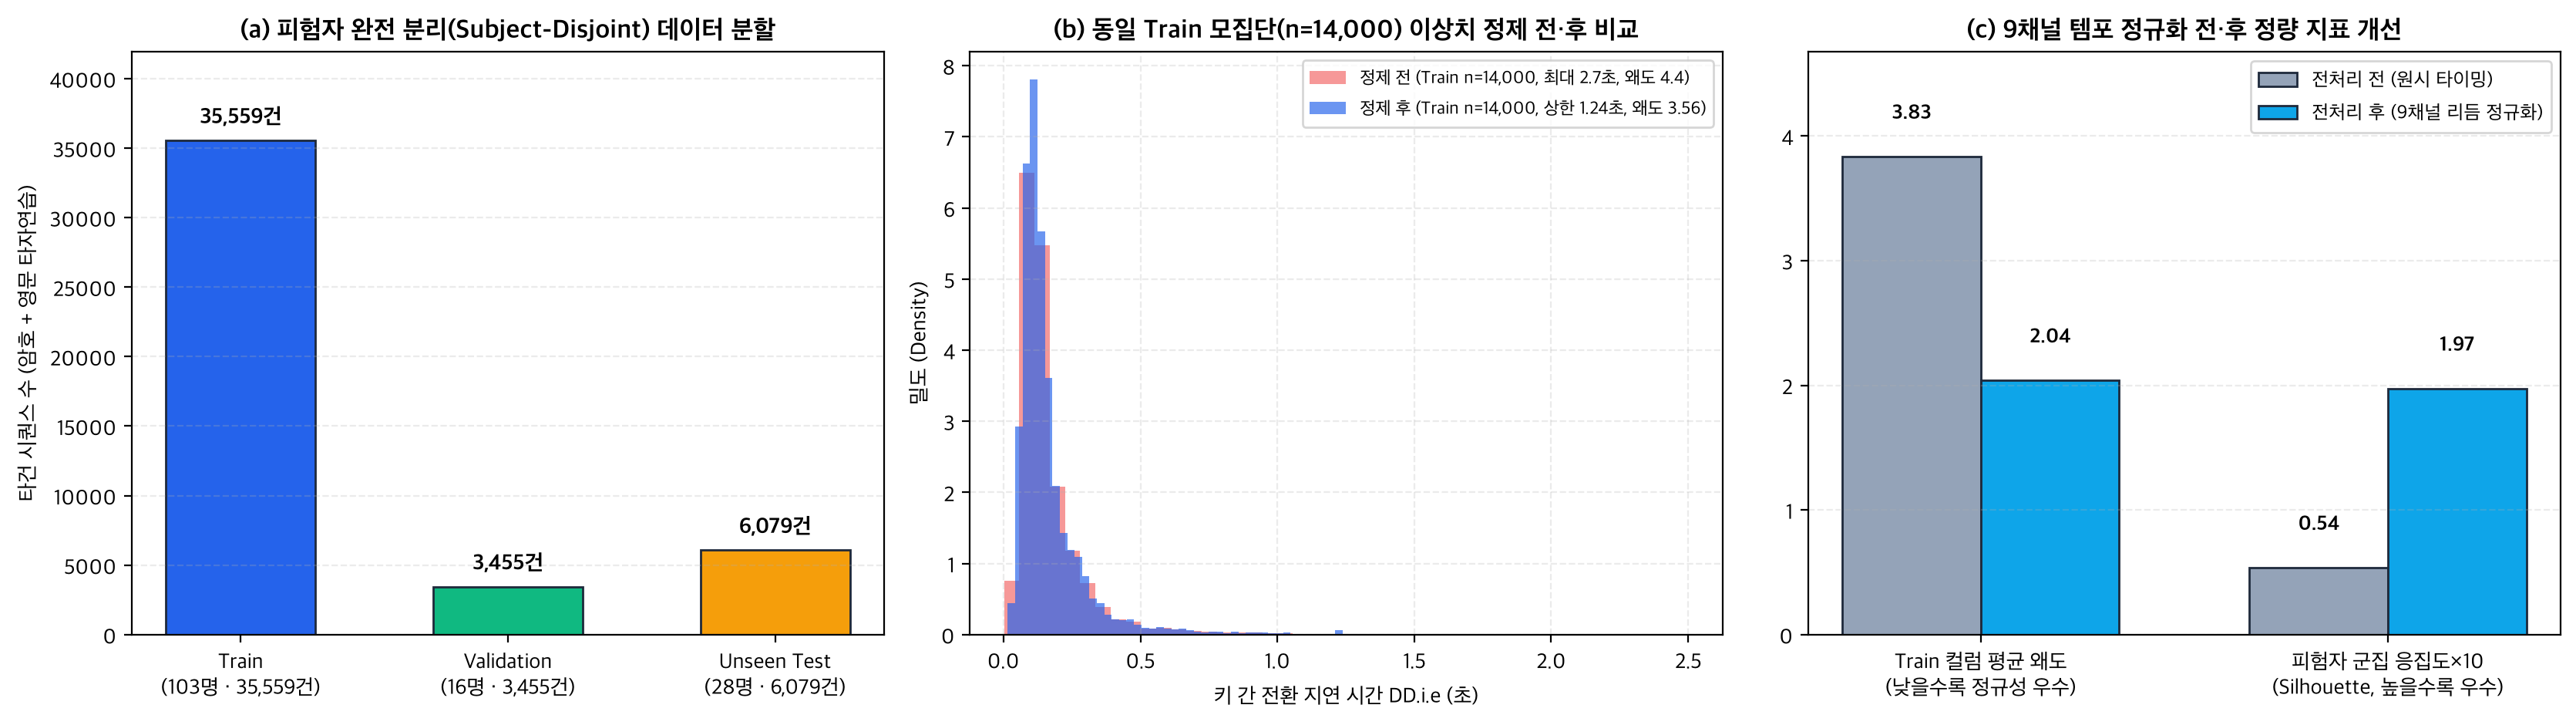

In [2]:
with tempfile.TemporaryDirectory() as _tmp_proc:
    splits, meta = prepare_full_pipeline(
        REPO_ROOT / 'data/raw/DSL-StrongPasswordData.csv',
        Path(_tmp_proc),
        seed=SEED,
    )
sentence_splits = meta.pop('_sentence_splits', {})
meta.pop('_keyrecs_fixed_train', None)
meta.pop('_keyrecs_runs', None)
meta.pop('_keyrecs_splits_subjs', None)

report = json.loads((OUT_ROOT / 'models/evaluation_report.json').read_text(encoding='utf-8'))
pw_cal = json.loads((OUT_ROOT / 'models/password_calibration.json').read_text(encoding='utf-8'))
style_rep = json.loads((OUT_ROOT / 'models/typing_style_analysis.json').read_text(encoding='utf-8'))
web_cfg = json.loads((OUT_ROOT / 'web/public/models/model_config.json').read_text(encoding='utf-8'))

kr_meta = meta['keyrecs_sentence_corpus']
assert kr_meta['total_lines'] == 562596 and kr_meta['valid_transitions'] == 562398
assert kr_meta['session_end_strokes'] == 198 and kr_meta['recovered_quote_rows'] == 26 and kr_meta['corrupt_rows'] == 0
assert kr_meta['sentence_stride_keys'] == 25 and kr_meta['sentence_window_keys'] == 25
print('=== [무손실 KeyRecs 파서 & 비중첩 창 검증 통과] ===')
print(json.dumps(kr_meta, indent=2, ensure_ascii=False))

print('\n=== [CMU 피험자 완전 분리 분할 (비율 % 포함)] ===')
print(json.dumps(meta['split_counts'], indent=2, ensure_ascii=False))

# 5단계 Test 코사인 실루엣 직접 재산출 및 리포트 일치 검증
n_test = len(splits['test'].df)
sils = {
    'silhouette_raw4_cosine': round(float(silhouette_score(np.stack([splits['test'].raw_holds[:, :-1], splits['test'].raw_holds[:, 1:], splits['test'].raw_dds, splits['test'].raw_uds], axis=1).reshape(n_test, -1), splits['test'].subject_ids, metric='cosine')), 4),
    'silhouette_clipped4_unscaled_cosine': round(float(silhouette_score(splits['test'].seq_unscaled[:, :4, :].reshape(n_test, -1), splits['test'].subject_ids, metric='cosine')), 4),
    'silhouette_clipped4_scaled_cosine': round(float(silhouette_score(splits['test'].seq_scaled[:, :4, :].reshape(n_test, -1), splits['test'].subject_ids, metric='cosine')), 4),
    'silhouette_bio9_cosine': round(float(silhouette_score(splits['test'].seq_scaled[:, :N_TIMING_CHANNELS, :].reshape(n_test, -1), splits['test'].subject_ids, metric='cosine')), 4),
    'silhouette_bio17_cosine': round(float(silhouette_score(splits['test'].seq_scaled[:, :N_CHANNELS, :].reshape(n_test, -1), splits['test'].subject_ids, metric='cosine')), 4),
}
for k, v in sils.items():
    assert abs(v - report['preprocessing'][k]) <= 1e-4, f'{k}: {v} != {report["preprocessing"][k]}'
ba = meta['preprocessing_before_after']
display(pd.DataFrame([
    {'항목': 'Train 모집단 크기 (동일 모집단 전·후)', '수치': f"{ba['population']} (n={ba['population_n']:,})"},
    {'항목': '평균 왜도 (전 -> 후)', '수치': f"{ba['before_mean_skewness']} -> {ba['after_mean_skewness']}"},
    {'항목': '평균 첨도 (전 -> 후)', '수치': f"{ba['before_mean_kurtosis']} -> {ba['after_mean_kurtosis']}"},
    *[{'항목': k, '수치': v} for k, v in sils.items()],
]))
ipy_display(Image(filename=str(OUT_ROOT / 'assets/figures/fig1_preprocessing_comparison.png'), width=960))

## 3. 공식 가중치 로드 · 실시간 순방향 추론 재현성(`±1e-5`) 검증 · 저장된 학습 곡선 확인
- 모델을 재학습하지 않고 `models/*.pt`를 로드하여 미학습 테스트셋(`splits['test']`)에 대해 순방향 추론을 수행한 뒤, `models/evaluation_report.json`에 기록된 공식 지표와 `1e-5` 이내로 완전 일치하는지 검증합니다.

In [3]:
chan_mean = np.array(meta['channel_mean'], dtype=np.float32)
chan_std = np.array(meta['channel_std'], dtype=np.float32)
val_trials = build_verification_trials(splits['val'], chan_mean, chan_std, k_shot=5, seed=SEED)
test_trials = build_verification_trials(splits['test'], chan_mean, chan_std, k_shot=5, seed=SEED)

# 1) ScaledManhattan
manhattan = ScaledManhattanDetector(shrinkage=0.35).fit_prior(splits['train'].raw_flat, splits['train'].subject_ids)
yv_m, sv_m = score_manhattan_trials(manhattan, splits['val'], val_trials)
thresh_m = find_optimal_val_threshold(yv_m, sv_m)
yt_m, st_m = score_manhattan_trials(manhattan, splits['test'], test_trials)
live_models = {'ScaledManhattan': summarize_metrics(yt_m, st_m, thresh_m)}

# 2) Vanilla1DCNN & Vanilla1DCNN_Aug (+ASNorm)
vanilla_net = Vanilla1DCNN(in_channels=N_CHANNELS, embed_dim=64)
vanilla_net.load_state_dict(torch.load(OUT_ROOT / 'models/vanilla_1dcnn.pt', map_location='cpu', weights_only=True))
vanilla_net.to(device).eval()
yv_v, sv_v, _ = score_embedding_trials(encode_sequences(vanilla_net, splits['val'].seq_scaled, device), encode_sequences(vanilla_net, val_trials['bot_seq'], device), val_trials, cohort=None, single_centroid=False)
yt_v, st_v, _ = score_embedding_trials(encode_sequences(vanilla_net, splits['test'].seq_scaled, device), encode_sequences(vanilla_net, test_trials['bot_seq'], device), test_trials, cohort=None, single_centroid=False)
live_models['Vanilla1DCNN'] = summarize_metrics(yt_v, st_v, find_optimal_val_threshold(yv_v, sv_v))

vanilla_aug = Vanilla1DCNN(in_channels=N_CHANNELS, embed_dim=64)
vanilla_aug.load_state_dict(torch.load(OUT_ROOT / 'models/vanilla_1dcnn_aug.pt', map_location='cpu', weights_only=True))
vanilla_aug.to(device).eval()
coh_va = compute_cohort_centroids(encode_sequences(vanilla_aug, splits['train'].seq_scaled, device), splits['train'].subject_ids)
ve_va = encode_sequences(vanilla_aug, splits['val'].seq_scaled, device)
vb_va = encode_sequences(vanilla_aug, val_trials['bot_seq'], device)
te_va = encode_sequences(vanilla_aug, splits['test'].seq_scaled, device)
tb_va = encode_sequences(vanilla_aug, test_trials['bot_seq'], device)
yv_va, sv_va, _ = score_embedding_trials(ve_va, vb_va, val_trials, cohort=None, single_centroid=False)
yt_va, st_va, _ = score_embedding_trials(te_va, tb_va, test_trials, cohort=None, single_centroid=False)
live_models['Vanilla1DCNN_Aug'] = summarize_metrics(yt_va, st_va, find_optimal_val_threshold(yv_va, sv_va))
yv_vas, sv_vas, _ = score_embedding_trials(ve_va, vb_va, val_trials, cohort=coh_va, single_centroid=False)
yt_vas, st_vas, _ = score_embedding_trials(te_va, tb_va, test_trials, cohort=coh_va, single_centroid=False)
live_models['Vanilla1DCNN_Aug_ASNorm'] = summarize_metrics(yt_vas, st_vas, find_optimal_val_threshold(yv_vas, sv_vas))

# 3) KeyPrintNet 9ch & KeyPrintNet 17ch
kp9 = KeyPrintNet(in_channels=N_TIMING_CHANNELS, hidden_channels=80, embed_dim=64, dropout=0.18)
kp9.load_state_dict(torch.load(OUT_ROOT / 'models/legacy/keyprint_net_9ch.pt', map_location='cpu', weights_only=True))
kp9.to(device).eval()
coh_9 = compute_cohort_centroids(encode_sequences(kp9, splits['train'].seq_scaled[:, :N_TIMING_CHANNELS], device), splits['train'].subject_ids)
yv_9, sv_9, _ = score_embedding_trials(encode_sequences(kp9, splits['val'].seq_scaled[:, :N_TIMING_CHANNELS], device), encode_sequences(kp9, val_trials['bot_seq'][:, :N_TIMING_CHANNELS], device), val_trials, cohort=coh_9)
yt_9, st_9, _ = score_embedding_trials(encode_sequences(kp9, splits['test'].seq_scaled[:, :N_TIMING_CHANNELS], device), encode_sequences(kp9, test_trials['bot_seq'][:, :N_TIMING_CHANNELS], device), test_trials, cohort=coh_9)
live_models['KeyPrintNet_9ch'] = summarize_metrics(yt_9, st_9, find_optimal_val_threshold(yv_9, sv_9))

kp17 = KeyPrintNet(in_channels=N_CHANNELS, hidden_channels=80, embed_dim=64, dropout=0.18)
kp17.load_state_dict(torch.load(OUT_ROOT / 'models/keyprint_net.pt', map_location='cpu', weights_only=True))
kp17.to(device).eval()
coh_17 = compute_cohort_centroids(encode_sequences(kp17, splits['train'].seq_scaled, device), splits['train'].subject_ids)
yv_17, sv_17, _ = score_embedding_trials(encode_sequences(kp17, splits['val'].seq_scaled, device), encode_sequences(kp17, val_trials['bot_seq'], device), val_trials, cohort=coh_17)
yt_17, st_17, _ = score_embedding_trials(encode_sequences(kp17, splits['test'].seq_scaled, device), encode_sequences(kp17, test_trials['bot_seq'], device), test_trials, cohort=coh_17)
live_models['KeyPrintNet'] = summarize_metrics(yt_17, st_17, find_optimal_val_threshold(yv_17, sv_17))

for m_name, live_m in live_models.items():
    rep_m = report['models'][m_name]
    for metric_key in ('eer', 'roc_auc', 'macro_f1'):
        diff = abs(live_m[metric_key] - rep_m[metric_key])
        assert diff <= 1e-5, f'{m_name}.{metric_key} mismatch: live={live_m[metric_key]} vs report={rep_m[metric_key]}'
print('모든 6개 통제 비교 모델 실시간 순방향 추론 지표가 evaluation_report.json과 1e-5 이내 완전 일치합니다!')

# 저장된 에포크 학습 로그 요약 및 학습 곡선 시각화
hist = report['histories']
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for label, key in [('Vanilla1DCNN', 'Vanilla1DCNN'), ('Vanilla1DCNN_Aug', 'Vanilla1DCNN_Aug'), ('KeyPrintNet 9ch', 'KeyPrintNet_9ch'), ('KeyPrintNet 17ch', 'KeyPrintNet')]:
    rows_h = hist.get(key, [])
    if rows_h:
        axes[0].plot([r['epoch'] for r in rows_h], [r['train_loss'] for r in rows_h], label=f'{label} (n={len(rows_h)} ep)')
        axes[1].plot([r['epoch'] for r in rows_h], [r['val_eer'] * 100 for r in rows_h], label=label)
axes[0].set_title('Saved Train Loss Curve'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].set_title('Saved Validation EER (%) ↓'); axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout(); plt.show()

모든 6개 통제 비교 모델 실시간 순방향 추론 지표가 evaluation_report.json과 1e-5 이내 완전 일치합니다!


/var/folders/_h/qp3l1w3555zb17znf4p_77_80000gn/T/ipykernel_75173/3410381430.py:70: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


## 4. 통제된 베이스라인 비교 · 실측 타인(`1,600`) vs 합성 봇(`200`) 분리 · 1:N 인물 식별 비교
- **과업 1 (1:1 검증)**: 동일 증강·동일 AS-Norm 채점을 부여한 `Vanilla1DCNN_Aug` / `Vanilla1DCNN_Aug_ASNorm` 통제 비교와, Validation 임계값에서의 실측 인간 침입자(`1,600`건) 대 매크로 봇(`200`건) 분리 성적을 함께 제시합니다.
- **과업 2 (1:N 식별)**: 초기 **3문장 단일질의 기준선(`k=3, q=1`)**과 실제 웹 서비스의 **5문장 등록 · 2문장 질의 배포 프로토콜(`k=5, q=2, open-set margin`)**을 명확히 구분해 비교합니다.

=== [§5.1] 1:1 통제 베이스라인 및 제안 모델 비교 (Unseen CMU 10명) ===


,모델,Val 임계값,Test Macro F1 ↑,ROC-AUC ↑,EER ↓,FAR / FRR
0,ScaledManhattan (통계 베이스라인),0.3863,0.7670,0.8384,23.97%,20.06% / 26.50%
1,Vanilla1DCNN (기본 무증강 · 무보정 코사인),0.5110,0.8280,0.9114,17.36%,15.17% / 19.22%
2,Vanilla1DCNN (+동일 템포·터치 증강),0.4893,0.8333,0.9129,16.03%,17.72% / 15.61%
3,Vanilla1DCNN (+동일 증강 + AS-Norm 코호트 보정),0.4645,0.8497,0.9247,14.56%,17.11% / 12.94%
4,KeyPrintNet 9ch (순수 타이밍 비밀번호 인코더),0.5218,0.8446,0.9216,15.03%,18.00% / 13.06%
5,KeyPrintNet 17ch (제안 문장·키위치 인코더),0.4727,0.8491,0.9318,14.39%,22.78% / 7.22%


=== [§5.1] 동일 Validation 임계값 기준 실측 인간 침입자(1,600) vs 합성 매크로 봇(200) 분리 ===


,모델,"실측 타인(1,600) AUC / EER / FAR",합성 봇(200) AUC / EER / FAR,"통합(1,800) AUC / EER / FAR"
0,ScaledManhattan (통계 베이스라인),0.8351 / 24.00% / 20.31%,0.8646 / 21.56% / 18.00%,0.8384 / 23.97% / 20.06%
1,Vanilla1DCNN (기본 무증강 · 무보정 코사인),0.9056 / 17.88% / 16.44%,0.9577 / 12.94% / 5.00%,0.9114 / 17.36% / 15.17%
2,Vanilla1DCNN (+동일 템포·터치 증강),0.9058 / 17.18% / 19.44%,0.9698 / 10.03% / 4.00%,0.9129 / 16.03% / 17.72%
3,Vanilla1DCNN (+동일 증강 + AS-Norm 코호트 보정),0.9201 / 14.97% / 18.12%,0.9614 / 10.97% / 9.00%,0.9247 / 14.56% / 17.11%
4,KeyPrintNet 9ch (순수 타이밍 비밀번호 인코더),0.9160 / 15.77% / 19.31%,0.9664 / 9.44% / 7.50%,0.9216 / 15.03% / 18.00%
5,KeyPrintNet 17ch (제안 문장·키위치 인코더),0.9248 / 15.71% / 25.06%,0.9881 / 6.14% / 4.50%,0.9318 / 14.39% / 22.78%


=== [§5.2] 1:N 인물 식별: 3문장 단일질의 기준선 vs 5문장·2문장 배포 프로토콜 ===


,프로토콜,모델,성능 요약 1,성능 요약 2
0,"CMU 동일 암호 10인 분류 (k=5, 교차 세션)",ScaledManhattan,Top-1 35.40%,Top-3 59.74%
1,"CMU 동일 암호 10인 분류 (k=5, 교차 세션)",Vanilla1DCNN,Top-1 44.97%,Top-3 80.74%
2,"CMU 동일 암호 10인 분류 (k=5, 교차 세션)",Vanilla1DCNN_Aug,Top-1 47.54%,Top-3 85.17%
3,"CMU 동일 암호 10인 분류 (k=5, 교차 세션)",Vanilla1DCNN_Aug_ASNorm,Top-1 48.69%,Top-3 88.17%
4,"CMU 동일 암호 10인 분류 (k=5, 교차 세션)",KeyPrintNet_9ch,Top-1 41.91%,Top-3 83.31%
5,"CMU 동일 암호 10인 분류 (k=5, 교차 세션)",KeyPrintNet,Top-1 48.26%,Top-3 88.60%
6,"KeyRecs 18인 폐쇄형 [3문장 단일질의 기준선 k=3, q=1] (keybo...",legacy_9ch,Top-1 당일 72.8% / 익일 61.4%,Top-3 당일 94.6% / 익일 90.3%
7,"KeyRecs 18인 폐쇄형 [3문장 단일질의 기준선 k=3, q=1] (keybo...",keyprint_17ch,Top-1 당일 84.4% / 익일 77.3%,Top-3 당일 98.4% / 익일 94.6%
8,"KeyRecs 18인 폐쇄형 [3문장 단일질의 기준선 k=3, q=1] (keybo...",keyprint_17ch_behavior,Top-1 당일 85.9% / 익일 81.3%,Top-3 당일 99.5% / 익일 96.5%
9,"KeyRecs 18인 폐쇄형 [3문장 단일질의 기준선 k=3, q=1] (keybo...",behavior_only,Top-1 당일 34.0% / 익일 32.6%,Top-3 당일 68.3% / 익일 64.5%


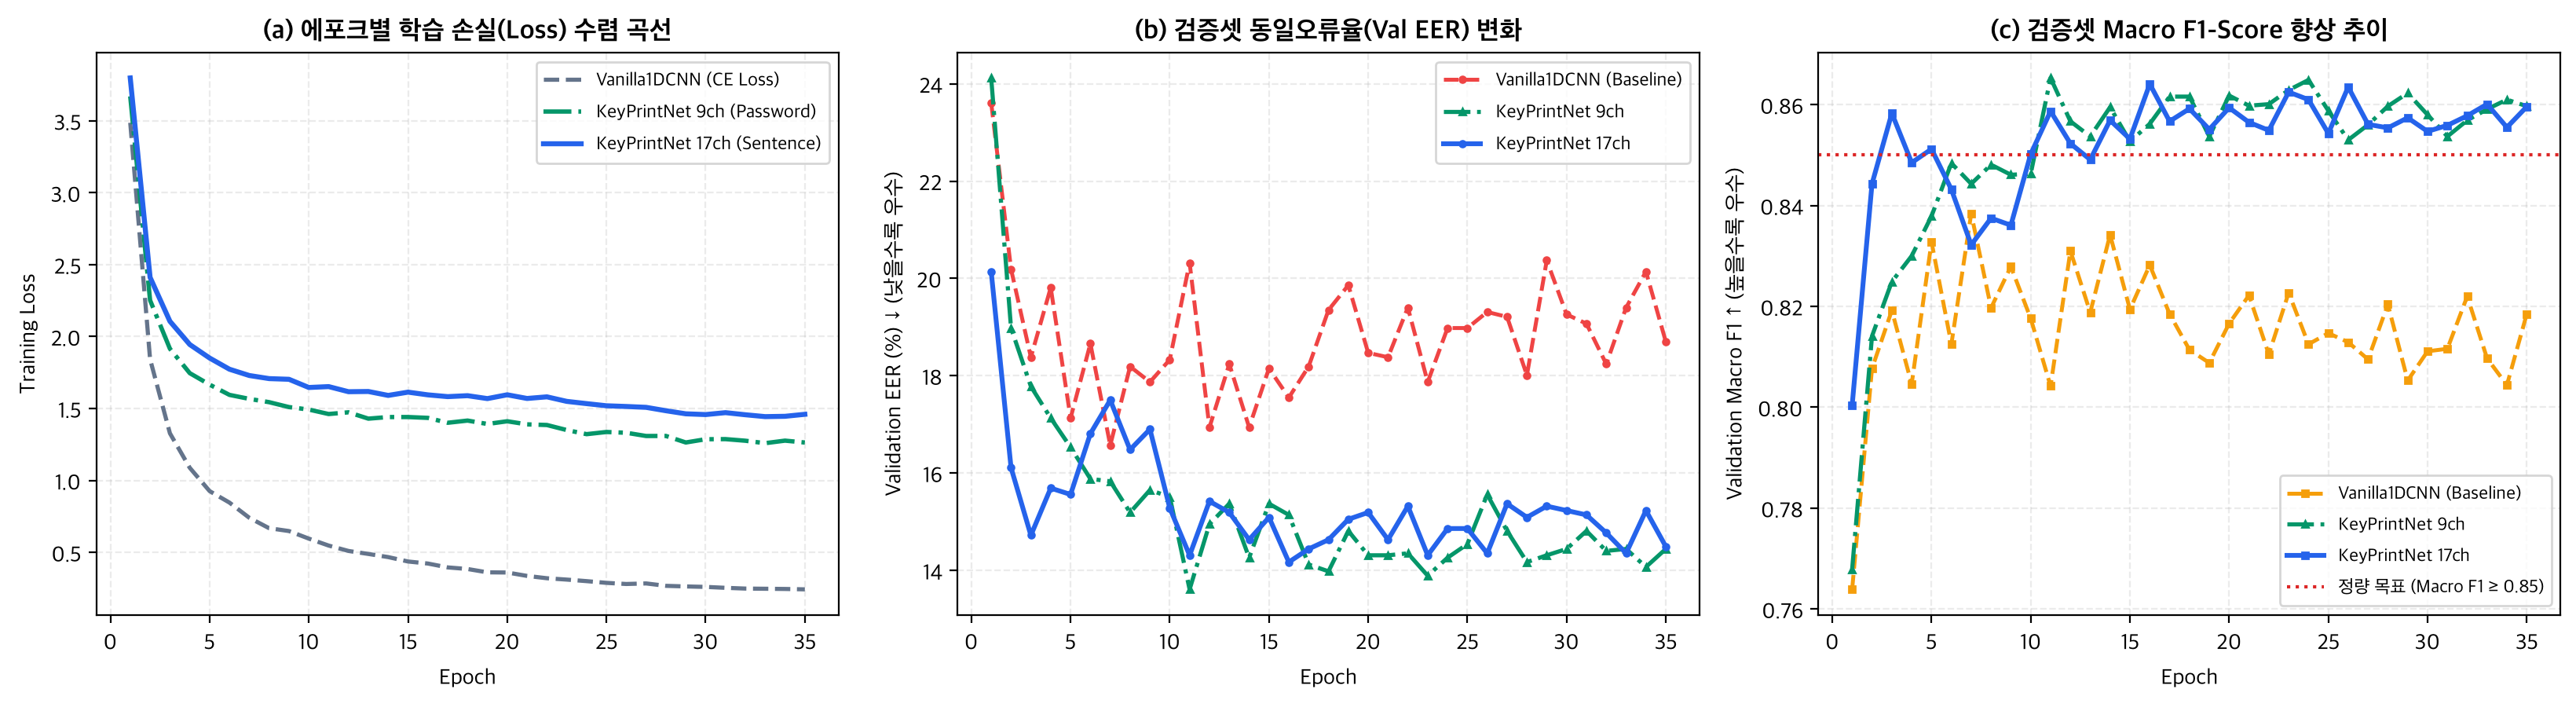

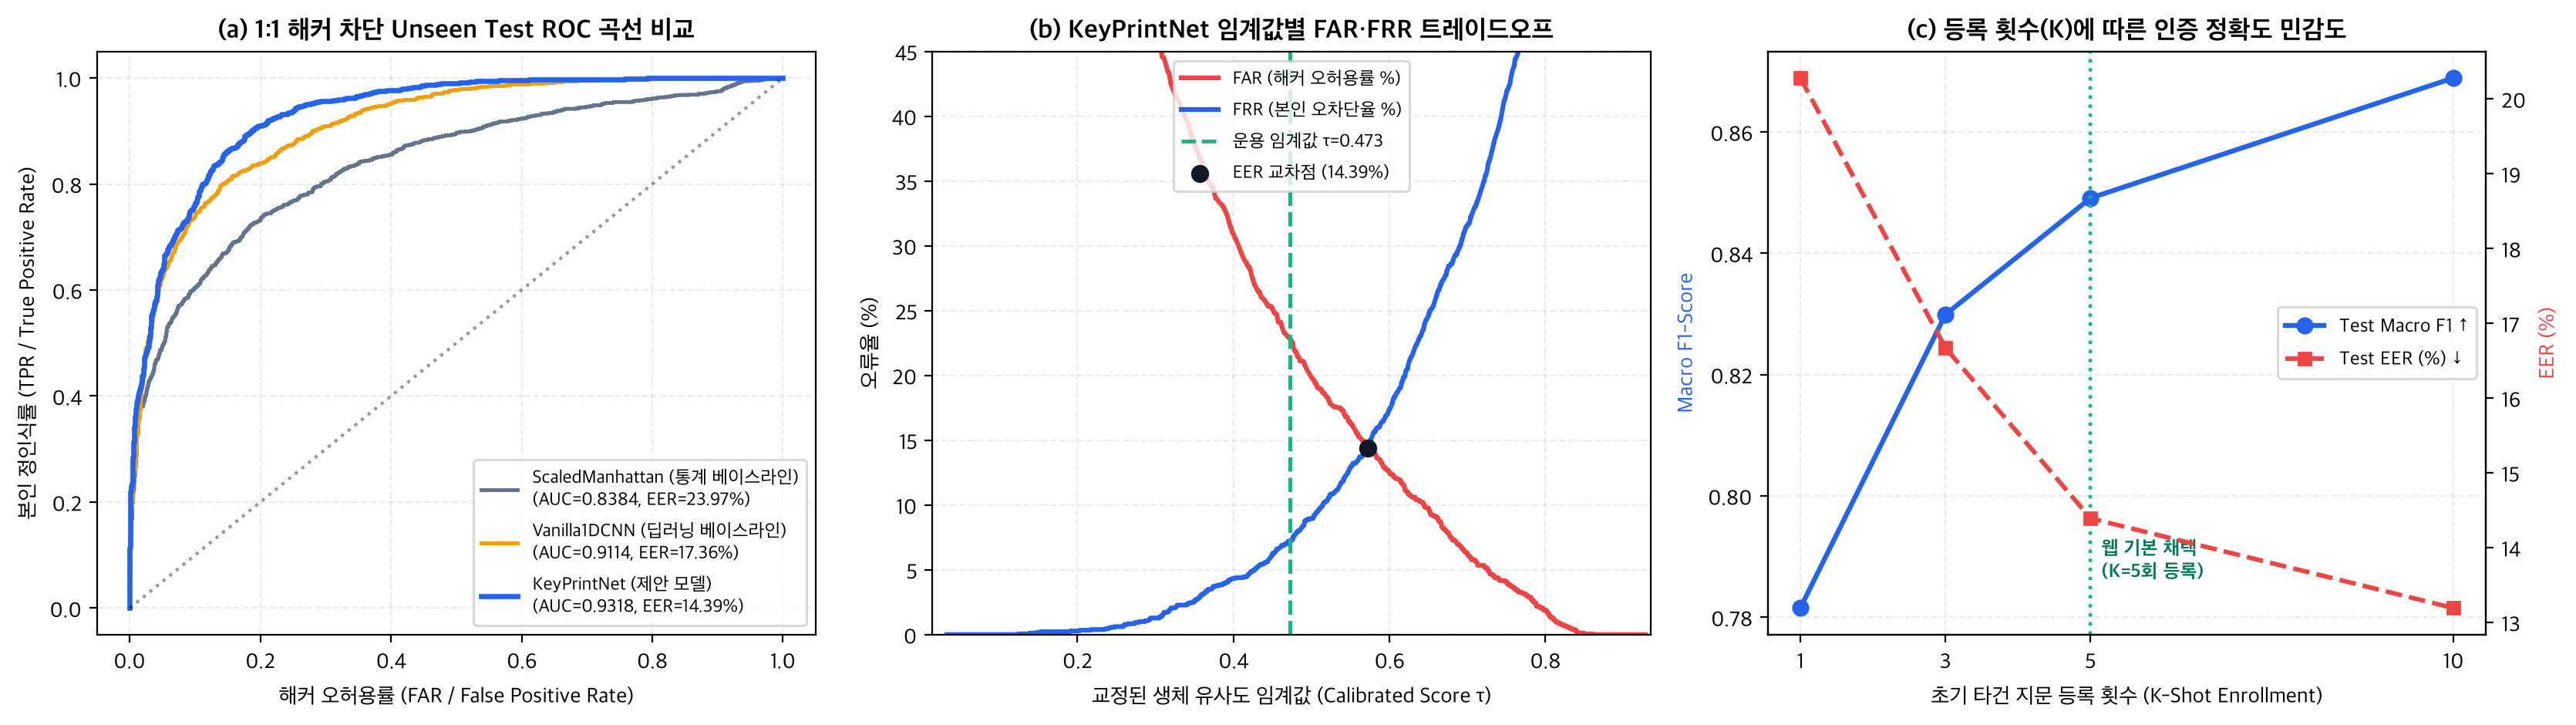

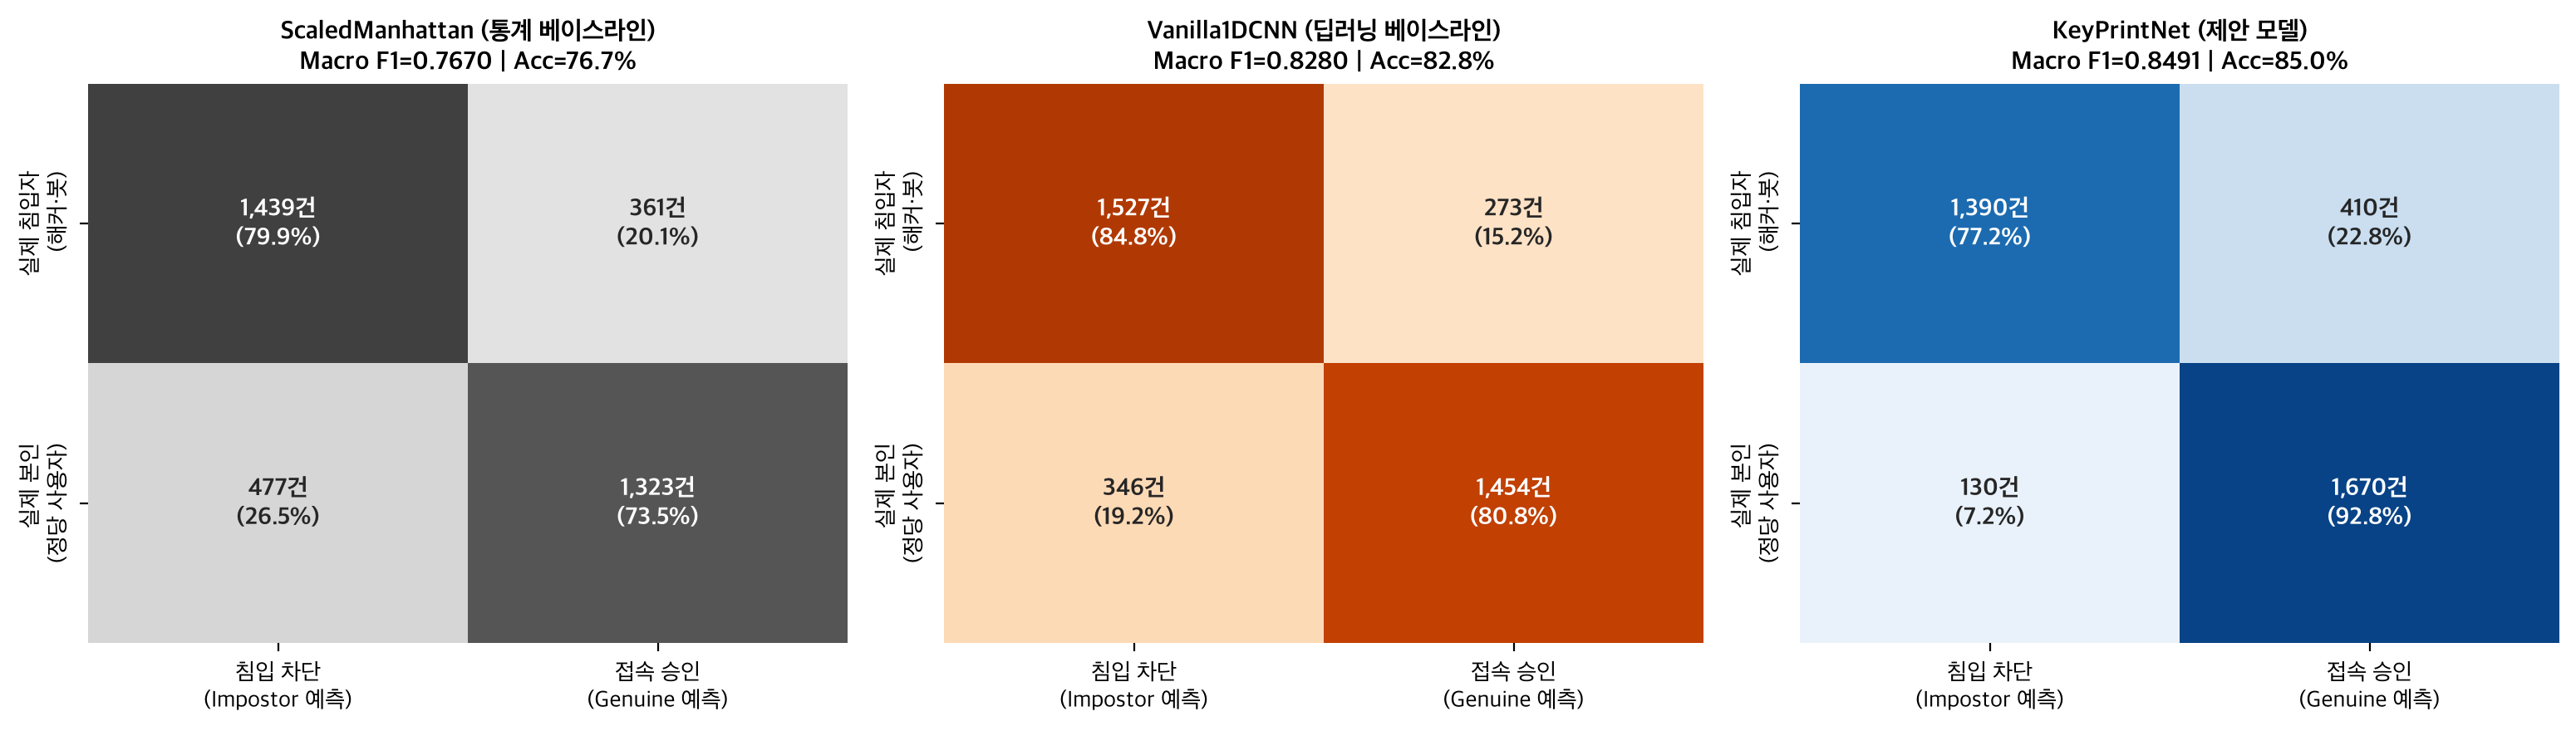

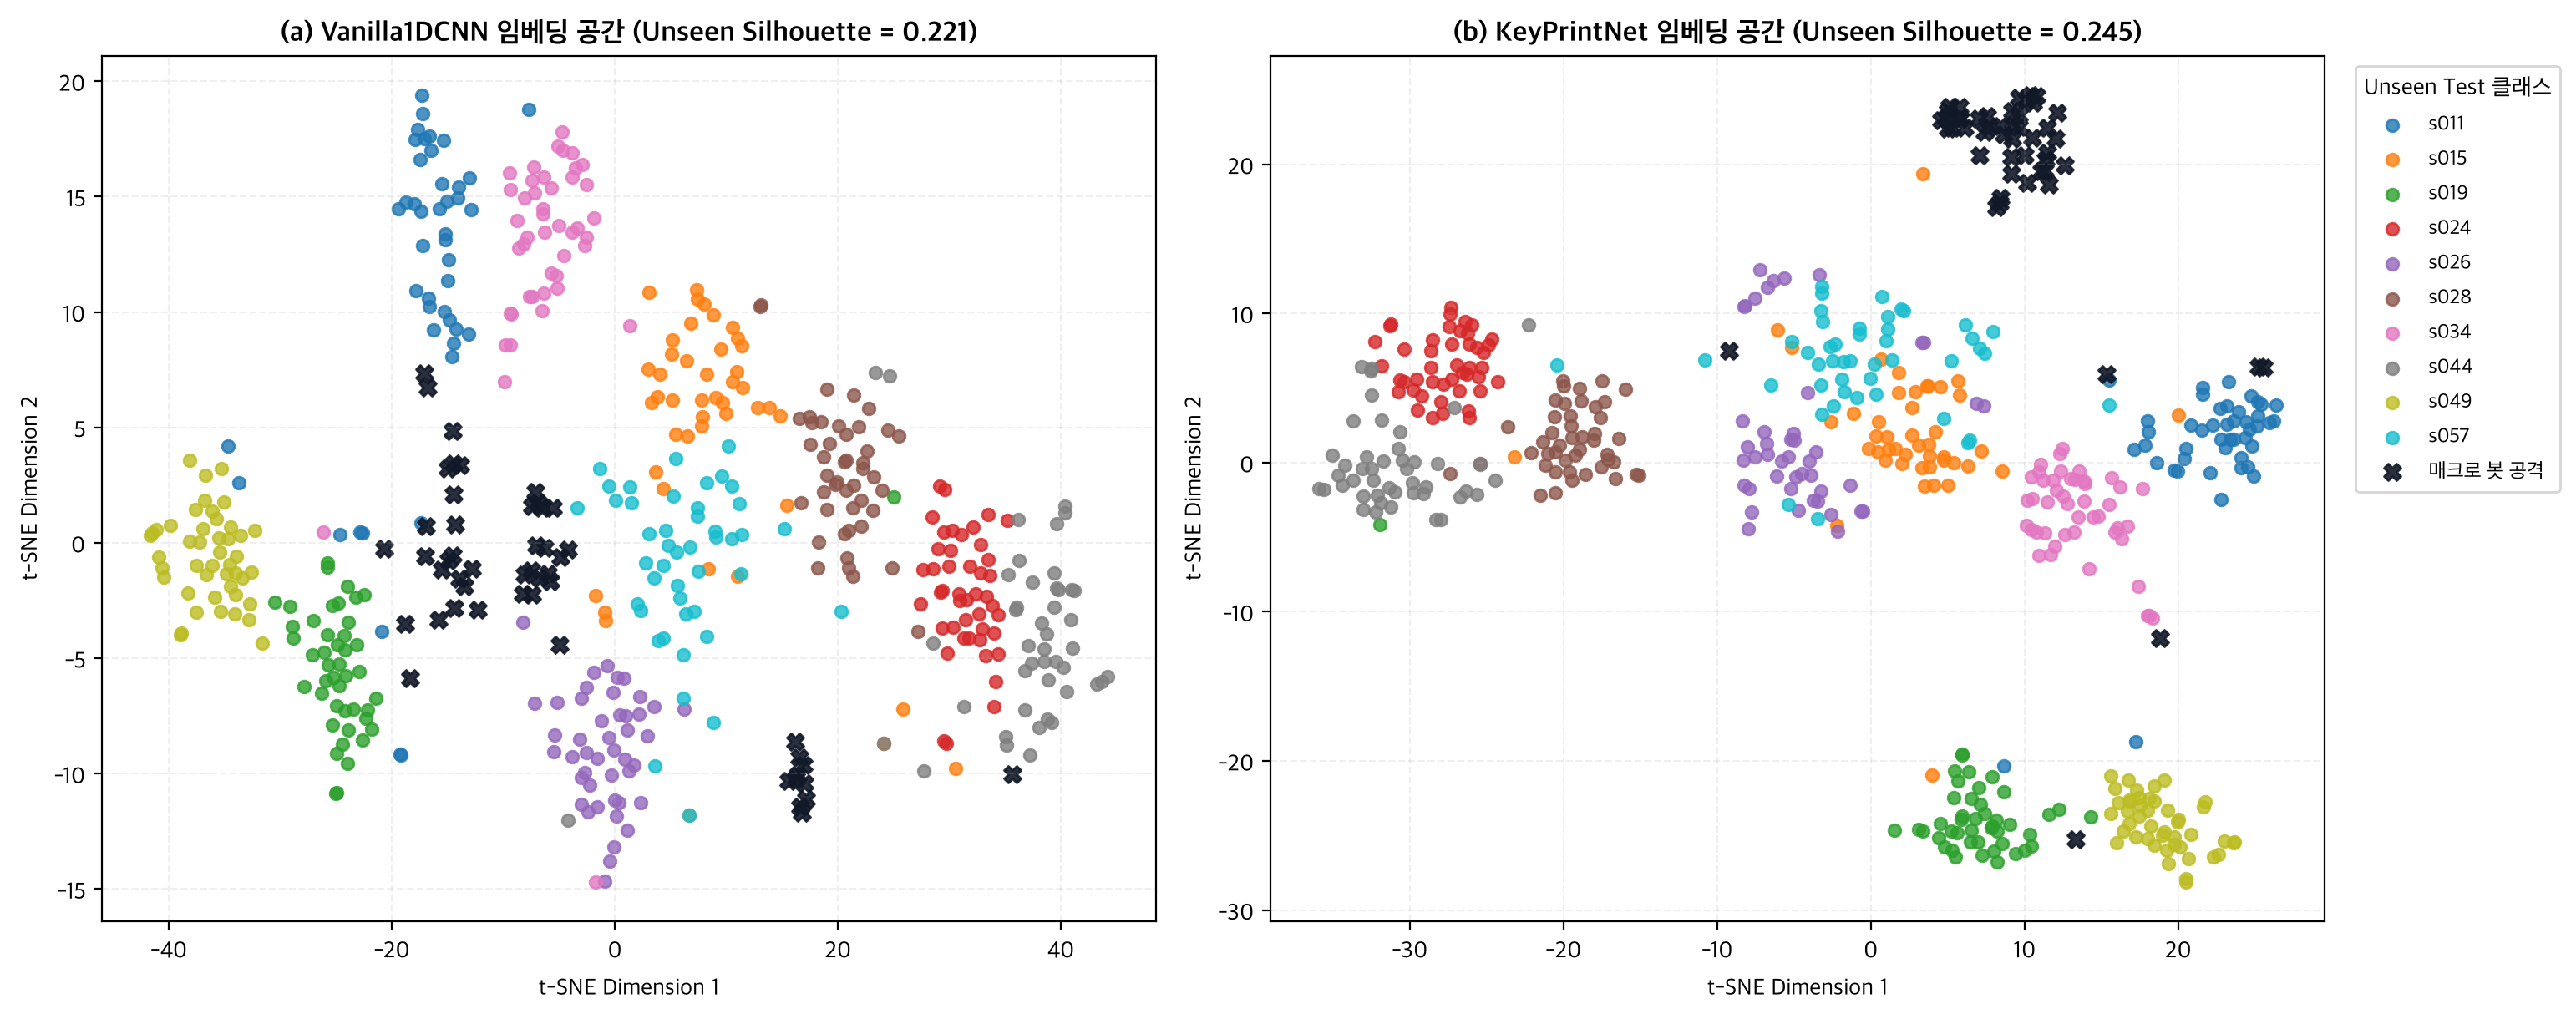

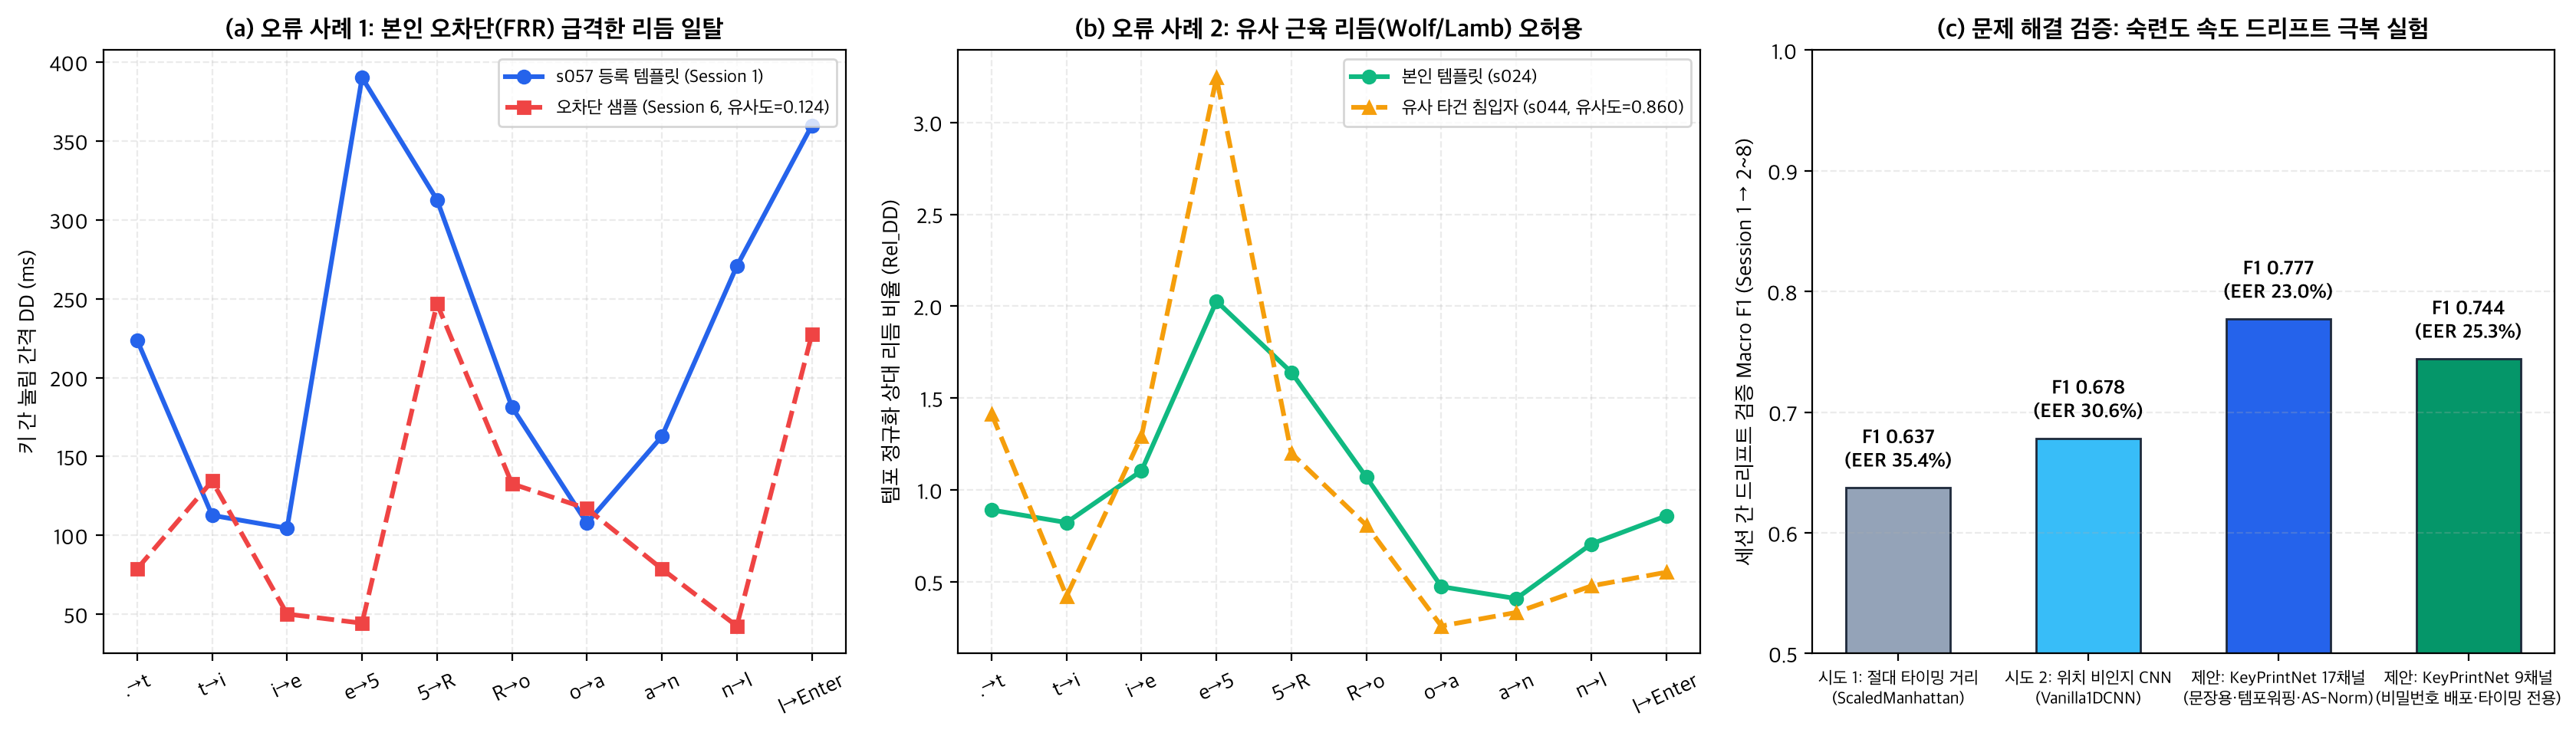

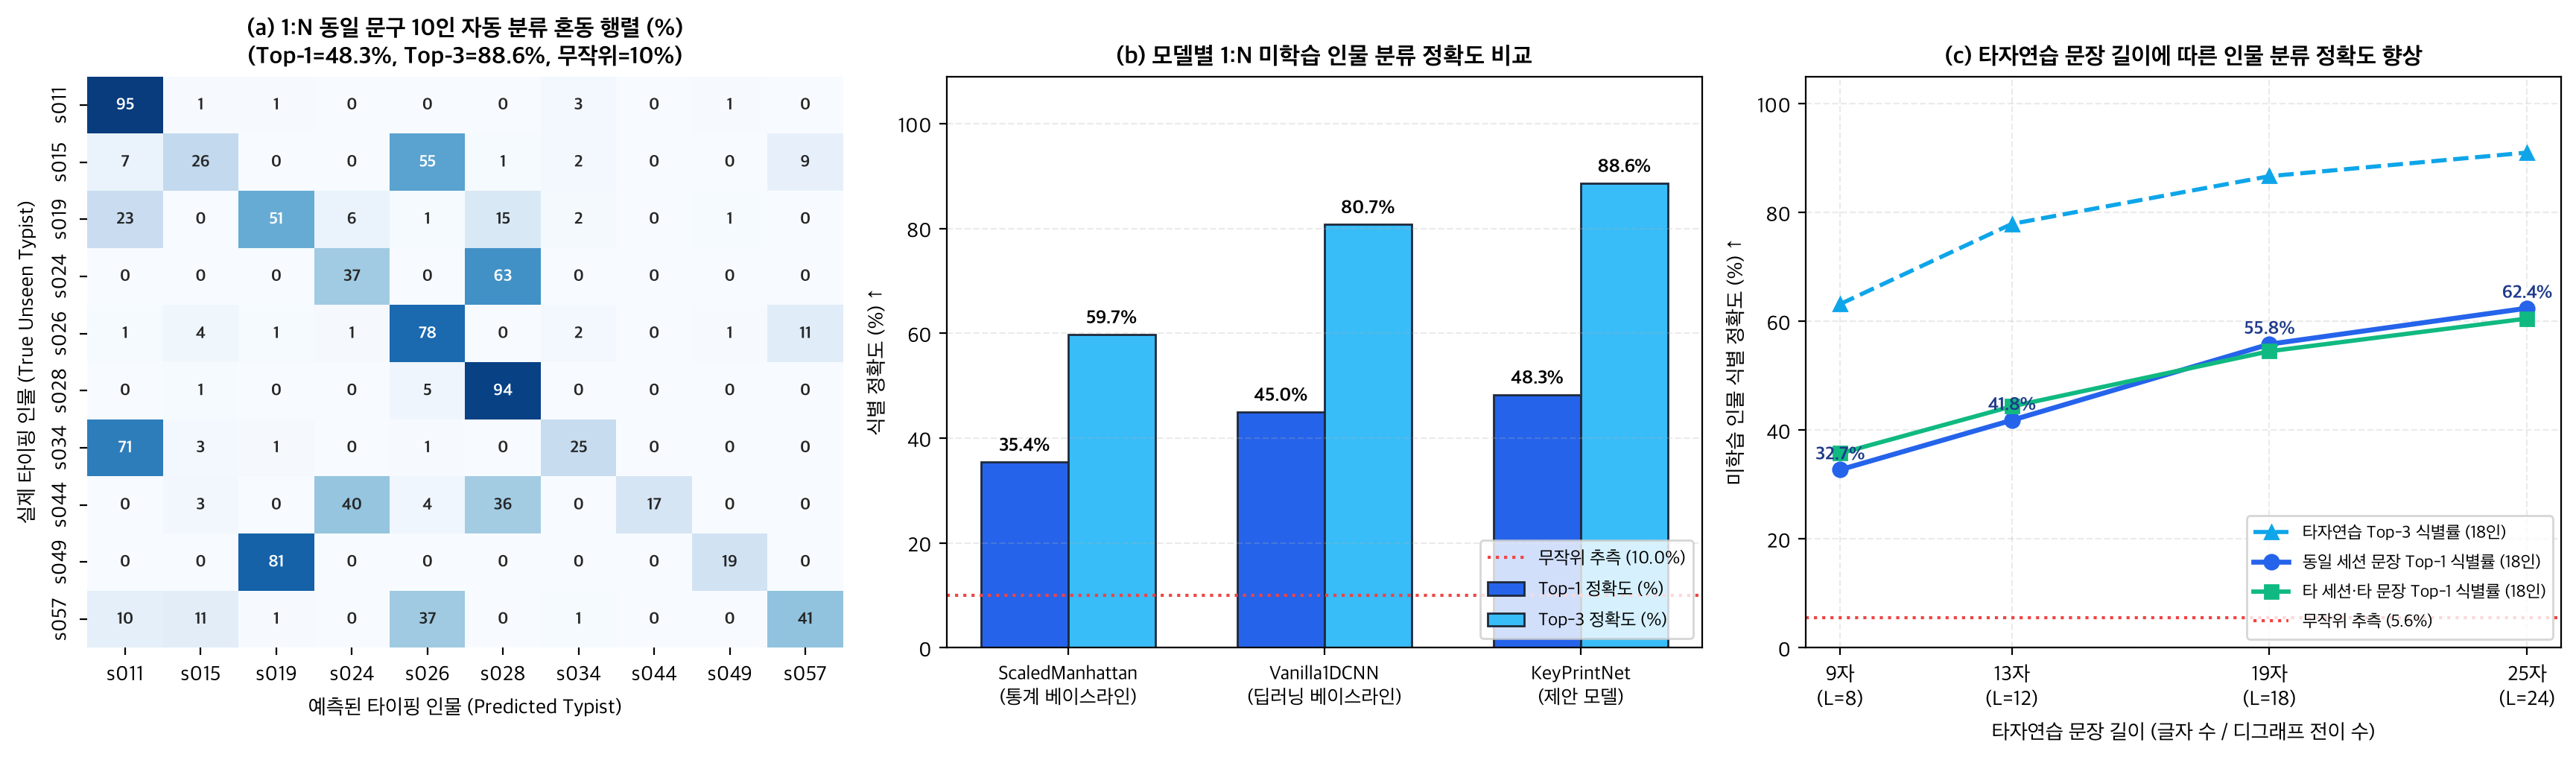

In [4]:
model_order = [
    ('ScaledManhattan', 'ScaledManhattan (통계 베이스라인)'),
    ('Vanilla1DCNN', 'Vanilla1DCNN (기본 무증강 · 무보정 코사인)'),
    ('Vanilla1DCNN_Aug', 'Vanilla1DCNN (+동일 템포·터치 증강)'),
    ('Vanilla1DCNN_Aug_ASNorm', 'Vanilla1DCNN (+동일 증강 + AS-Norm 코호트 보정)'),
    ('KeyPrintNet_9ch', 'KeyPrintNet 9ch (순수 타이밍 비밀번호 인코더)'),
    ('KeyPrintNet', 'KeyPrintNet 17ch (제안 문장·키위치 인코더)'),
]
tbl_rows, brk_rows = [], []
for key, label in model_order:
    m = report['models'][key]
    ib = m['impostor_breakdown']
    tbl_rows.append({
        '모델': label,
        'Val 임계값': m['threshold'],
        'Test Macro F1 ↑': m['macro_f1'],
        'ROC-AUC ↑': m['roc_auc'],
        'EER ↓': f"{m['eer']*100:.2f}%",
        'FAR / FRR': f"{m['far']*100:.2f}% / {m['frr']*100:.2f}%",
    })
    brk_rows.append({
        '모델': label,
        '실측 타인(1,600) AUC / EER / FAR': f"{ib['human_only']['roc_auc']:.4f} / {ib['human_only']['eer']*100:.2f}% / {ib['human_only']['far']*100:.2f}%",
        '합성 봇(200) AUC / EER / FAR': f"{ib['bot_only']['roc_auc']:.4f} / {ib['bot_only']['eer']*100:.2f}% / {ib['bot_only']['far']*100:.2f}%",
        '통합(1,800) AUC / EER / FAR': f"{ib['combined']['roc_auc']:.4f} / {ib['combined']['eer']*100:.2f}% / {ib['combined']['far']*100:.2f}%",
    })
print('=== [§5.1] 1:1 통제 베이스라인 및 제안 모델 비교 (Unseen CMU 10명) ===')
display(pd.DataFrame(tbl_rows))
print('=== [§5.1] 동일 Validation 임계값 기준 실측 인간 침입자(1,600) vs 합성 매크로 봇(200) 분리 ===')
display(pd.DataFrame(brk_rows))

fu = report['feature_upgrade']
id_rows = []
for m_key in ('ScaledManhattan', 'Vanilla1DCNN', 'Vanilla1DCNN_Aug', 'Vanilla1DCNN_Aug_ASNorm', 'KeyPrintNet_9ch', 'KeyPrintNet'):
    r = report['typist_identification_1toN']['cmu_10way'][m_key]
    id_rows.append({'프로토콜': 'CMU 동일 암호 10인 분류 (k=5, 교차 세션)', '모델': m_key, '성능 요약 1': f"Top-1 {r['top1_accuracy']*100:.2f}%", '성능 요약 2': f"Top-3 {r['top3_accuracy']*100:.2f}%"})
for dev_name, blk in fu['web_faithful_identification'].items():
    for m_key, res in blk.items():
        id_rows.append({
            '프로토콜': f'KeyRecs 18인 폐쇄형 [3문장 단일질의 기준선 k=3, q=1] ({dev_name})',
            '모델': m_key,
            '성능 요약 1': f"Top-1 당일 {res['same_session']['top1_accuracy']*100:.1f}% / 익일 {res['cross_session']['top1_accuracy']*100:.1f}%",
            '성능 요약 2': f"Top-3 당일 {res['same_session']['top3_accuracy']*100:.1f}% / 익일 {res['cross_session']['top3_accuracy']*100:.1f}%",
        })
ap = fu['arena_protocol']
for dev_name in ('keyboard', 'touch'):
    g10_base = ap[dev_name]['gallery_10']['single_sentence_enroll3']
    g10_dep = ap[dev_name]['gallery_10']['two_sentences_enroll5_margin']
    id_rows.append({
        '프로토콜': f'Arena 10인 개방형 [3문장 단일질의 기준선 k=3, q=1] ({dev_name})',
        '모델': 'KeyPrintNet 17ch + Behavior',
        '성능 요약 1': f"정식별 {g10_base['correct_accept']*100:.1f}% / 오식별 {g10_base['misidentified']*100:.1f}%",
        '성능 요약 2': f"외부인 오수락 {g10_base['outsider_accepted']*100:.1f}%",
    })
    id_rows.append({
        '프로토콜': f'Arena 10인 개방형 [5문장 등록 · 2문장 질의 배포 프로토콜 k=5, q=2] ({dev_name})',
        '모델': 'KeyPrintNet 17ch + Behavior + Margin',
        '성능 요약 1': f"정식별 {g10_dep['correct_accept']*100:.1f}% / 오식별 {g10_dep['misidentified']*100:.1f}%",
        '성능 요약 2': f"외부인 오수락 {g10_dep['outsider_accepted']*100:.1f}% (기준선 대비 개선)",
    })
print('=== [§5.2] 1:N 인물 식별: 3문장 단일질의 기준선 vs 5문장·2문장 배포 프로토콜 ===')
display(pd.DataFrame(id_rows))
for fig_name in ['fig2_learning_curves.png', 'fig3_roc_det_kshot.png', 'fig4_confusion_matrices.png', 'fig5_embedding_tsne.png', 'fig6_error_analysis_and_ablation.png', 'fig7_typist_identification.png']:
    ipy_display(Image(filename=str(OUT_ROOT / 'assets/figures' / fig_name), width=960))

## 5. `§5.6~5.7` 비밀번호 전이 · Occurrence 분리 합성 · 배포 임계값 일치 · 문제 해결 절제 로그
- **인코더 선택 격리**: `password_transfer_val`(`Validation` 피험자 전용) 결과만으로 비밀번호 인코더를 선택하고, `password_transfer_other_content`(`Test` 피험자 전용)로 최종 검증합니다.
- **디그래프 합성 표본 격리**: 같은 날(`Session 1`) 등록과 본인 질의가 동일한 원본 타건(`occ_id`)을 절대 재사용하지 않도록 분리(`disjoint_occ_enforced=True`)했습니다.
- **대문자 습관 배포 임계값 일치**: 브라우저(`biometrics.js`)와 동일하게 `base_tau + tau_offset`에서 평가합니다.

=== [Validation 전용 인코더 선택 기록] ===
{
  "selection_split": "val_only",
  "val_cost_legacy_9ch": 0.6203,
  "val_cost_keyprint_17ch": 0.7063,
  "chosen_encoder": "legacy_9ch"
}

=== [§5.6] 디그래프 합성 메타데이터 (동일 세션 occ_id 완전 분리) ===
{
  "val": {
    "disjoint_occ_enforced": true,
    "same_day_rows_verified": 3360,
    "excluded_person_string_pairs": 40,
    "total_generated_attempts": 6720,
    "generated_attempts": 6720
  },
  "test": {
    "disjoint_occ_enforced": true,
    "same_day_rows_verified": 5958,
    "excluded_person_string_pairs": 87,
    "total_generated_attempts": 11916,
    "generated_attempts": 11916
  }
}

=== [§5.7] 대문자 입력 습관 결합 (배포 임계값 base_tau + tau_offset 일치 평가) ===
{
  "weight": 3.0,
  "tau_offset": 1.1996,
  "deployed_threshold_no_capitals": 1.165,
  "deployed_threshold_with_capitals": 2.3646,
  "test_without": {
    "far": 0.1821,
    "frr": 0.1096
  },
  "test_with": {
    "far": 0.11,
    "frr": 0.1667
  }
}

=== [password_calibration.json 요약 (Val/Test 분리 검증)] ===


,시나리오,본인/침입자,AS-Norm AUC (FAR/FRR),Dual AUC (FAR/FRR)
0,cmu_val_kb,1080/1080,0.929 (15.5%/15.7%),0.931 (42.7%/1.7%)
1,cmu_val_touch,1080/1080,0.836 (20.4%/30.3%),0.846 (63.9%/1.3%)
2,cmu_test_kb,1800/1800,0.915 (17.1%/14.9%),0.922 (37.0%/3.3%)
3,cmu_test_touch,1800/1800,0.855 (17.0%/28.4%),0.856 (56.1%/5.2%)
4,krfixed_val_kb,1000/900,0.750 (27.4%/32.9%),0.766 (18.4%/44.1%)
5,krfixed_val_touch,1000/900,0.611 (32.8%/53.4%),0.656 (22.1%/64.3%)
6,krfixed_test_kb,1795/3060,0.755 (31.8%/30.9%),0.808 (21.3%/35.7%)
7,krfixed_test_touch,1795/3060,0.666 (44.0%/32.3%),0.727 (31.4%/33.7%)
8,words_same_day_val_kb,32/96,0.958 (27.1%/6.2%),0.944 (41.7%/6.2%)
9,words_cross_day_val_kb,4/48,0.938 (47.9%/0.0%),0.953 (39.6%/0.0%)


=== [typing_style_analysis.json 피험자 집계 & 분산 분해] ===
{
  "participant_counts": {
    "raw_corpus_participants": 99,
    "raw_participants_both_sessions": 99,
    "clean_chunk_participants": 96,
    "tempo_matching_test_participants": 18
  },
  "variance_decomposition": {
    "digraph_interval": {
      "people": 96,
      "items": 74,
      "share": {
        "key_layout": 0.0798,
        "person_speed": 0.1974,
        "person_rhythm": 0.1479,
        "attempt_noise": 0.5748
      }
    },
    "key_hold": {
      "people": 96,
      "items": 21,
      "share": {
        "key_layout": 0.0438,
        "person_speed": 0.3554,
        "person_rhythm": 0.1042,
        "attempt_noise": 0.4965
      }
    }
  },
  "same_speed_ideal_eer": {
    "password_9_intervals": 0.3616,
    "password_9_intervals_plus_10_holds": 0.3159,
    "one_sentence_60_intervals": 0.1738,
    "two_sentences_120_intervals": 0.0915
  }
}

=== [§9.2 문제 해결 사례 재현 절제 실험 (Tempo Normalization & Backspace Stitch)] ===
{
  "te

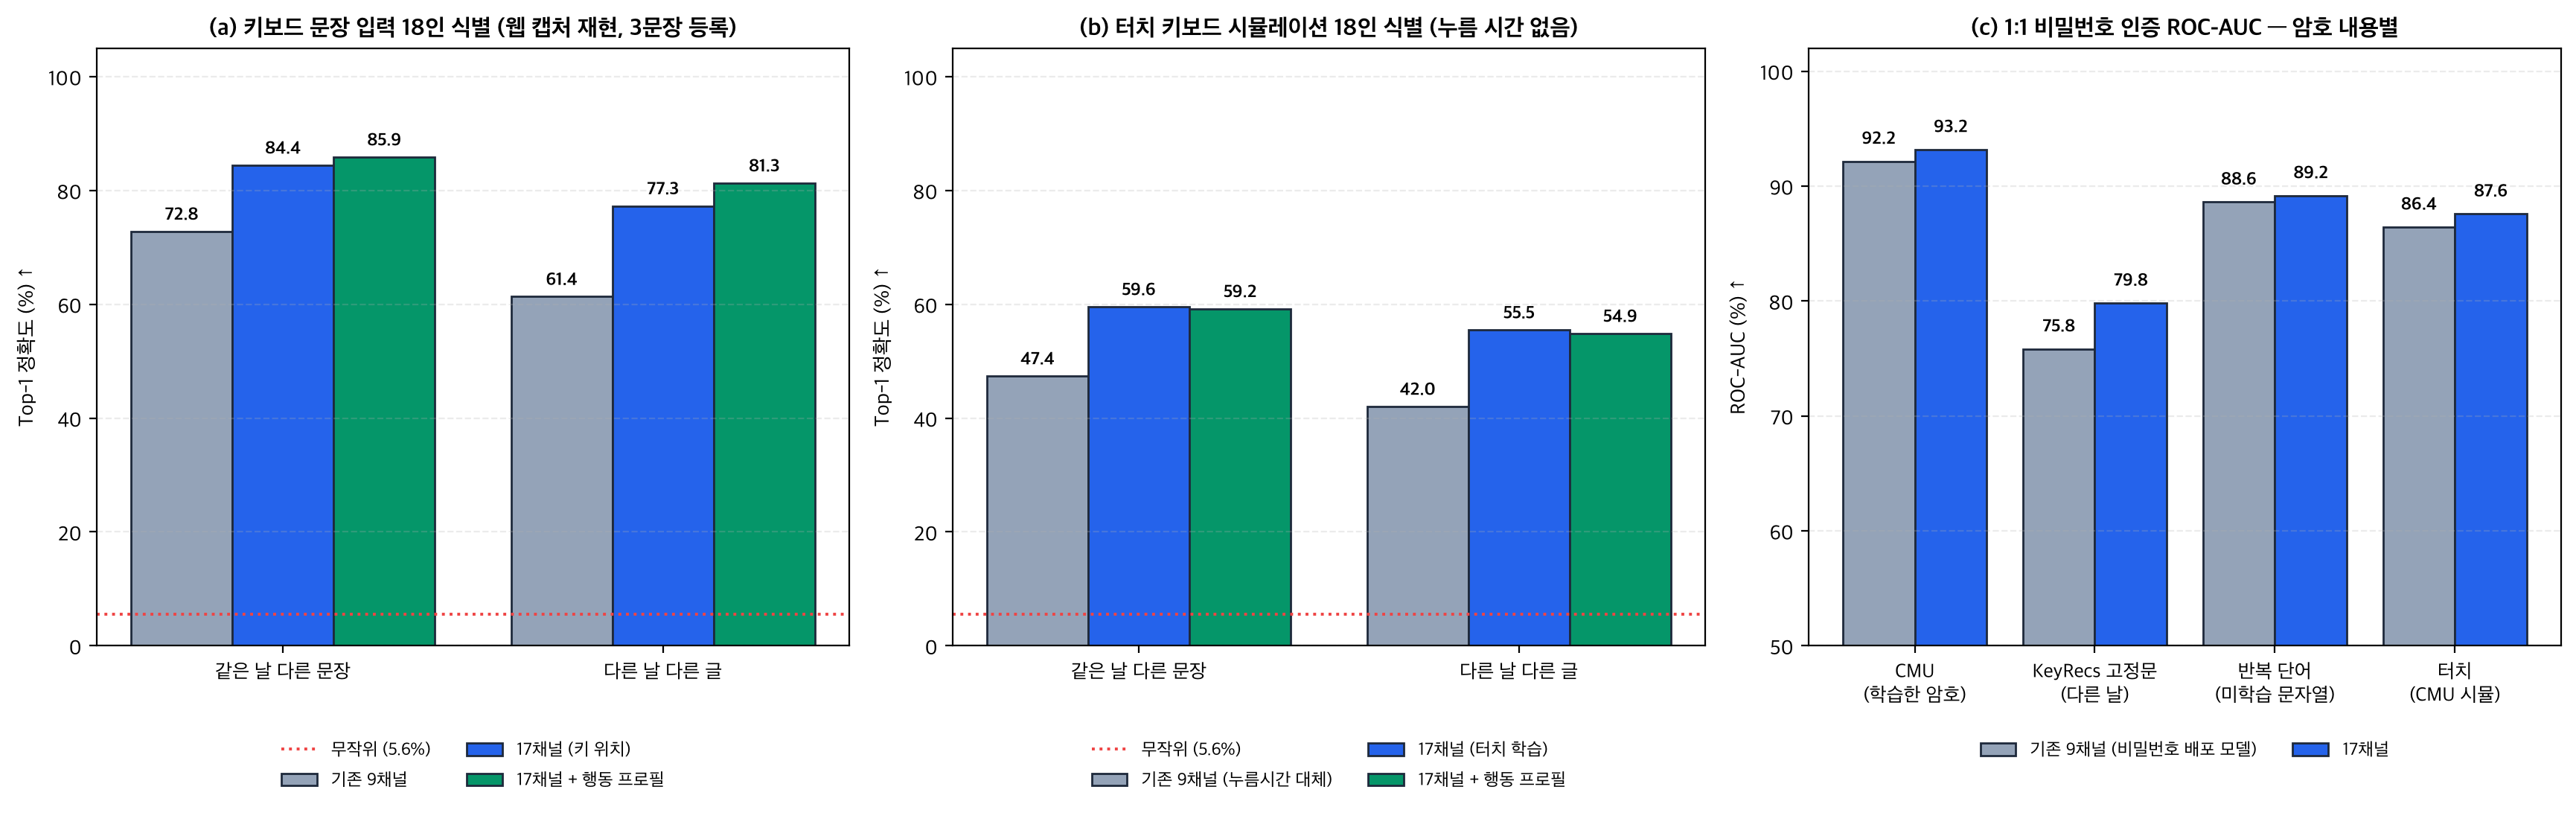

In [5]:
print('=== [Validation 전용 인코더 선택 기록] ===')
print(json.dumps(fu['password_encoder_selection'], indent=2, ensure_ascii=False))

us = fu['password_user_strings']
print('\n=== [§5.6] 디그래프 합성 메타데이터 (동일 세션 occ_id 완전 분리) ===')
print(json.dumps(us['synthesis_metadata'], indent=2, ensure_ascii=False))

cm = fu['password_capital_method']
print('\n=== [§5.7] 대문자 입력 습관 결합 (배포 임계값 base_tau + tau_offset 일치 평가) ===')
print(json.dumps({
    'weight': cm['weight'],
    'tau_offset': cm['tau_offset'],
    'deployed_threshold_no_capitals': cm['deployed_threshold_no_capitals'],
    'deployed_threshold_with_capitals': cm['deployed_threshold_with_capitals'],
    'test_without': cm['test_without'],
    'test_with': cm['test_with'],
}, indent=2, ensure_ascii=False))

print('\n=== [password_calibration.json 요약 (Val/Test 분리 검증)] ===')
assert pw_cal['split_isolation']['val_test_pooled'] is False
cal_rows = [
    {'시나리오': k, '본인/침입자': f"{v['num_genuine']}/{v['num_impostor']}",
     'AS-Norm AUC (FAR/FRR)': f"{v['as_norm_auc']:.3f} ({v['as_norm']['far']*100:.1f}%/{v['as_norm']['frr']*100:.1f}%)",
     'Dual AUC (FAR/FRR)': f"{v['dual_auc']:.3f} ({v['dual']['far']*100:.1f}%/{v['dual']['frr']*100:.1f}%)"}
    for k, v in pw_cal['scenarios'].items()
]
display(pd.DataFrame(cal_rows))

print('=== [typing_style_analysis.json 피험자 집계 & 분산 분해] ===')
print(json.dumps({'participant_counts': style_rep['participant_counts'], 'variance_decomposition': style_rep['variance_decomposition'], 'same_speed_ideal_eer': style_rep['same_speed_ideal_eer']}, indent=2, ensure_ascii=False))

print('\n=== [§9.2 문제 해결 사례 재현 절제 실험 (Tempo Normalization & Backspace Stitch)] ===')
print(json.dumps(report['troubleshooting_ablations'], indent=2, ensure_ascii=False))
ipy_display(Image(filename=str(OUT_ROOT / 'assets/figures/fig8_feature_upgrade.png'), width=960))

## 6. 웹 배포용 ONNX 가변 길이 정밀도(`max_err < 1e-5`) 및 스키마 `v4` 해시 무결성 검증

In [6]:
assert web_cfg['schema_version'] == 4 and web_cfg['preprocess_version'] == 'kp-preproc-v4'
sha17 = hashlib.sha256((OUT_ROOT / 'web/public/models/keyprint_net.onnx').read_bytes()).hexdigest()
sha9 = hashlib.sha256((OUT_ROOT / 'web/public/models/keyprint_net_password.onnx').read_bytes()).hexdigest()
expected_hash = hashlib.sha256(f'{sha17}:{sha9}'.encode('utf-8')).hexdigest()[:16]
assert web_cfg['onnx_sha256'] == {'sentence_17ch': sha17, 'password_9ch': sha9}
assert web_cfg['model_hash'] == expected_hash
for sp in web_cfg['mvp_sample_profiles']:
    assert sp['schemaVersion'] == 4 and sp['preprocessVersion'] == 'kp-preproc-v4' and sp['modelHash'] == expected_hash
print(f'Schema v4 & ONNX SHA-256 검증 통과 | model_hash={expected_hash}')

for title, onnx_file, pt_file, n_ch in [
    ('문장용 KeyPrintNet 17채널', OUT_ROOT / 'web/public/models/keyprint_net.onnx', OUT_ROOT / 'models/keyprint_net.pt', N_CHANNELS),
    ('비밀번호용 KeyPrintNet 9채널', OUT_ROOT / 'web/public/models/keyprint_net_password.onnx', OUT_ROOT / 'models/legacy/keyprint_net_9ch.pt', N_TIMING_CHANNELS),
]:
    sess = ort.InferenceSession(str(onnx_file), providers=['CPUExecutionProvider'])
    cpu_net = KeyPrintNet(in_channels=n_ch, hidden_channels=80, embed_dim=64, dropout=0.0)
    cpu_net.load_state_dict(torch.load(pt_file, map_location='cpu', weights_only=True))
    cpu_net.eval()
    print(f'[{title}] ONNX 파일 크기: {onnx_file.stat().st_size / 1024:.2f} KB')
    for seq_len in [5, 10, 18, 24, 32]:
        sample_in = np.random.RandomState(seq_len).randn(1, n_ch, seq_len).astype(np.float32)
        with torch.no_grad():
            pt_emb = cpu_net(torch.from_numpy(sample_in)).numpy()
        t0 = time.perf_counter()
        ort_emb = sess.run(['biometric_embedding'], {'keystroke_seq': sample_in})[0]
        dt_ms = (time.perf_counter() - t0) * 1000
        max_err = float(np.max(np.abs(pt_emb - ort_emb)))
        assert max_err < 1e-5, f'{title} L={seq_len} max_err={max_err}'
        print(f'  L={seq_len:2d} ({seq_len+1:2d}자) -> 출력 {ort_emb.shape} | PyTorch-ONNX 최대 오차: {max_err:.2e} | 추론 {dt_ms:.3f} ms')

Schema v4 & ONNX SHA-256 검증 통과 | model_hash=ac38471759213dd1
[문장용 KeyPrintNet 17채널] ONNX 파일 크기: 599.37 KB
  L= 5 ( 6자) -> 출력 (1, 64) | PyTorch-ONNX 최대 오차: 1.71e-07 | 추론 0.272 ms
  L=10 (11자) -> 출력 (1, 64) | PyTorch-ONNX 최대 오차: 2.16e-07 | 추론 0.261 ms
  L=18 (19자) -> 출력 (1, 64) | PyTorch-ONNX 최대 오차: 3.13e-07 | 추론 0.301 ms
  L=24 (25자) -> 출력 (1, 64) | PyTorch-ONNX 최대 오차: 1.71e-07 | 추론 0.262 ms
  L=32 (33자) -> 출력 (1, 64) | PyTorch-ONNX 최대 오차: 1.94e-07 | 추론 0.391 ms
[비밀번호용 KeyPrintNet 9채널] ONNX 파일 크기: 591.87 KB
  L= 5 ( 6자) -> 출력 (1, 64) | PyTorch-ONNX 최대 오차: 1.94e-07 | 추론 0.228 ms
  L=10 (11자) -> 출력 (1, 64) | PyTorch-ONNX 최대 오차: 1.27e-07 | 추론 0.167 ms
  L=18 (19자) -> 출력 (1, 64) | PyTorch-ONNX 최대 오차: 2.38e-07 | 추론 0.254 ms
  L=24 (25자) -> 출력 (1, 64) | PyTorch-ONNX 최대 오차: 2.10e-07 | 추론 0.297 ms
  L=32 (33자) -> 출력 (1, 64) | PyTorch-ONNX 최대 오차: 2.27e-07 | 추론 0.288 ms
